# Repeated Padding (RepPad) for Sequential Recommendation
## Applied to H&M Personalized Fashion Recommendations

**Paper:** *Repeated Padding for Sequential Recommendation* — Dang et al., RecSys 2024  
**Team:** Joori Shareef · Sarah Aldarwish · Rahaf Alhodali

---
### Notebook Overview
1. Environment Setup
2. H&M Data Loading & Preprocessing
3. Sequential Dataset Construction
4. RepPad Data Augmentation (from paper Algorithm 1)
5. Model Training — GRU4Rec & SASRec (using RepPad repo code)
6. Evaluation — HR@K and NDCG@K
7. Results Comparison

## 1. Environment Setup

In [1]:
import os, sys, random, math, time
import numpy as np
import pandas as pd
from collections import defaultdict
from copy import deepcopy
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# ── Paths ─────────────────────────────────────────────────────────────────────
HM_PATH     = '/kaggle/input/competitions/h-and-m-personalized-fashion-recommendations'
REPPAD_PATH = '/kaggle/input/datasets/rahafalhothali/reppad-main'  # kept for reference only
OUTPUT_PATH = '/kaggle/working'

# ── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device  : {DEVICE}')
print(f'PyTorch : {torch.__version__}')
print(f'Python  : {sys.version}')
if torch.cuda.is_available():
    print(f'GPU     : {torch.cuda.get_device_name(0)}')
    print(f'GPU mem : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

Device  : cuda
PyTorch : 2.10.0+cu128
Python  : 3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]
GPU     : Tesla T4
GPU mem : 15.6 GB


## 2. H&M Data Loading & Preprocessing

In [2]:
# ── Load transactions ─────────────────────────────────────────────────────────
print('Loading transactions...')
transactions = pd.read_csv(
    os.path.join(HM_PATH, 'transactions_train.csv'),
    usecols=['t_dat', 'customer_id', 'article_id'],
    dtype={'customer_id': str, 'article_id': str}
)
transactions['t_dat'] = pd.to_datetime(transactions['t_dat'])
print(f'Total transactions: {len(transactions):,}')
print(transactions.head())

Loading transactions...
Total transactions: 31,788,324
       t_dat                                        customer_id  article_id
0 2018-09-20  000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...  0663713001
1 2018-09-20  000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...  0541518023
2 2018-09-20  00007d2de826758b65a93dd24ce629ed66842531df6699...  0505221004
3 2018-09-20  00007d2de826758b65a93dd24ce629ed66842531df6699...  0685687003
4 2018-09-20  00007d2de826758b65a93dd24ce629ed66842531df6699...  0685687004


In [3]:
# ── 5-core filtering (keep users/items with >= 5 interactions) ────────────────
# This matches the paper's preprocessing step (Section 3.2).
def k_core_filter(df, k=5, user_col='customer_id', item_col='article_id'):
    """Iteratively apply k-core filtering until stable."""
    while True:
        prev_len = len(df)
        # Filter items
        item_counts = df[item_col].value_counts()
        df = df[df[item_col].isin(item_counts[item_counts >= k].index)]
        # Filter users
        user_counts = df[user_col].value_counts()
        df = df[df[user_col].isin(user_counts[user_counts >= k].index)]
        if len(df) == prev_len:
            break
    return df.reset_index(drop=True)

print('Applying 5-core filtering...')
df = k_core_filter(transactions, k=5)
print(f'After filtering — transactions: {len(df):,}')
print(f'Unique users : {df["customer_id"].nunique():,}')
print(f'Unique items : {df["article_id"].nunique():,}')

Applying 5-core filtering...
After filtering — transactions: 30,756,449
Unique users : 925,154
Unique items : 91,511


In [4]:
# ── Build user/item ID mappings ───────────────────────────────────────────────
# IDs start from 1 so that 0 can serve as the padding token.
users = sorted(df['customer_id'].unique())
items = sorted(df['article_id'].unique())

user2id = {u: i+1 for i, u in enumerate(users)}
item2id = {it: i+1 for i, it in enumerate(items)}

df['user_id'] = df['customer_id'].map(user2id)
df['item_id'] = df['article_id'].map(item2id)

NUM_USERS = len(users)
NUM_ITEMS = len(items)
print(f'NUM_USERS = {NUM_USERS:,}  |  NUM_ITEMS = {NUM_ITEMS:,}')

NUM_USERS = 925,154  |  NUM_ITEMS = 91,511


## 3. Sequential Dataset Construction

In [5]:
# ── Sort interactions chronologically and build per-user sequences ─────────────
df_sorted = df.sort_values(['user_id', 't_dat'])

user_sequences = (
    df_sorted.groupby('user_id')['item_id']
    .apply(list)
    .to_dict()
)

# Statistics
seq_lengths = [len(v) for v in user_sequences.values()]
print(f'Sequence length — min: {min(seq_lengths)}, '
      f'max: {max(seq_lengths)}, '
      f'avg: {np.mean(seq_lengths):.1f}, '
      f'median: {np.median(seq_lengths):.1f}')

Sequence length — min: 5, max: 1895, avg: 33.2, median: 18.0


In [6]:
# ── Subsample to 30k users for feasible training ─────────────────────────────
MAX_TRAIN_USERS = 30_000

all_uids = list(user_sequences.keys())
print(f'Total users before subsampling: {len(all_uids):,}')

if len(all_uids) > MAX_TRAIN_USERS:
    random.seed(SEED)
    sampled_uids   = random.sample(all_uids, MAX_TRAIN_USERS)
    user_sequences = {u: user_sequences[u] for u in sampled_uids}

print(f'Users after subsampling: {len(user_sequences):,}')
# Expected batches will print after hyperparameters are defined

Total users before subsampling: 925,154
Users after subsampling: 30,000


In [7]:
# ── Hyperparameters — matching Section 3.5 of the paper ──────────────────────
MAX_SEQ_LEN = 50       # paper uses 50 for short-sequence datasets
EMBED_DIM   = 64       # paper: embedding size = 64
BATCH_SIZE  = 64       # paper uses 256, reduced to 64 for GPU memory
LR          = 0.001    # paper: Adam lr = 0.001
NUM_EPOCHS  = 200      # high ceiling — early stopping handles termination
PATIENCE    = 20       # paper: "early stopping if no improvement for 20 epochs"
TOP_K       = [5, 10, 20]  # paper reports HR@K and NDCG@K for K ∈ {5, 10, 20}
NUM_NEG     = 100      # negative samples for sampled evaluation

import gc
gc.collect()
torch.cuda.empty_cache()
print(f'MAX_SEQ_LEN : {MAX_SEQ_LEN}')
print(f'EMBED_DIM   : {EMBED_DIM}')
print(f'BATCH_SIZE  : {BATCH_SIZE}')
print(f'PATIENCE    : {PATIENCE} epochs  (matches paper)')
print(f'NUM_EPOCHS  : {NUM_EPOCHS} max   (early stopping will trigger first)')
print(f'GPU free    : {torch.cuda.mem_get_info()[0]/1e9:.2f} GB')

MAX_SEQ_LEN : 50
EMBED_DIM   : 64
BATCH_SIZE  : 64
PATIENCE    : 20 epochs  (matches paper)
NUM_EPOCHS  : 200 max   (early stopping will trigger first)
GPU free    : 15.53 GB


In [8]:
# ── Leave-one-out train / val / test split ────────────────────────────────────
# Paper Section 3.4: last item → test, second-to-last → validation, rest → training.
train_seqs = {}   # user_id → list of training item ids
val_seqs   = {}   # user_id → (train_items, val_target)
test_seqs  = {}   # user_id → (train_items + val_item, test_target)

for uid, seq in user_sequences.items():
    if len(seq) < 3:          # need at least train / val / test
        continue
    train_seqs[uid] = seq[:-2]
    val_seqs[uid]   = (seq[:-2], seq[-2])
    test_seqs[uid]  = (seq[:-1], seq[-1])

print(f'Users with valid splits: {len(train_seqs):,}')

Users with valid splits: 30,000


=== H&M Sequence Length Statistics ===
Total users : 30,000
Min         : 5
Max         : 1895
Mean        : 33.4
Median      : 18.0
Std         : 45.5

=== Sequence Categories ===
Short  (<10 items)   : 8,181 (27.3%)
Medium (10-30 items) : 11,714 (39.0%)
Long   (>=30 items)  : 10,105 (33.7%)

=== RepPad Feasibility ===
Users that can benefit from RepPad with MAX_SEQ_LEN=50: 18,058 (60.2%)


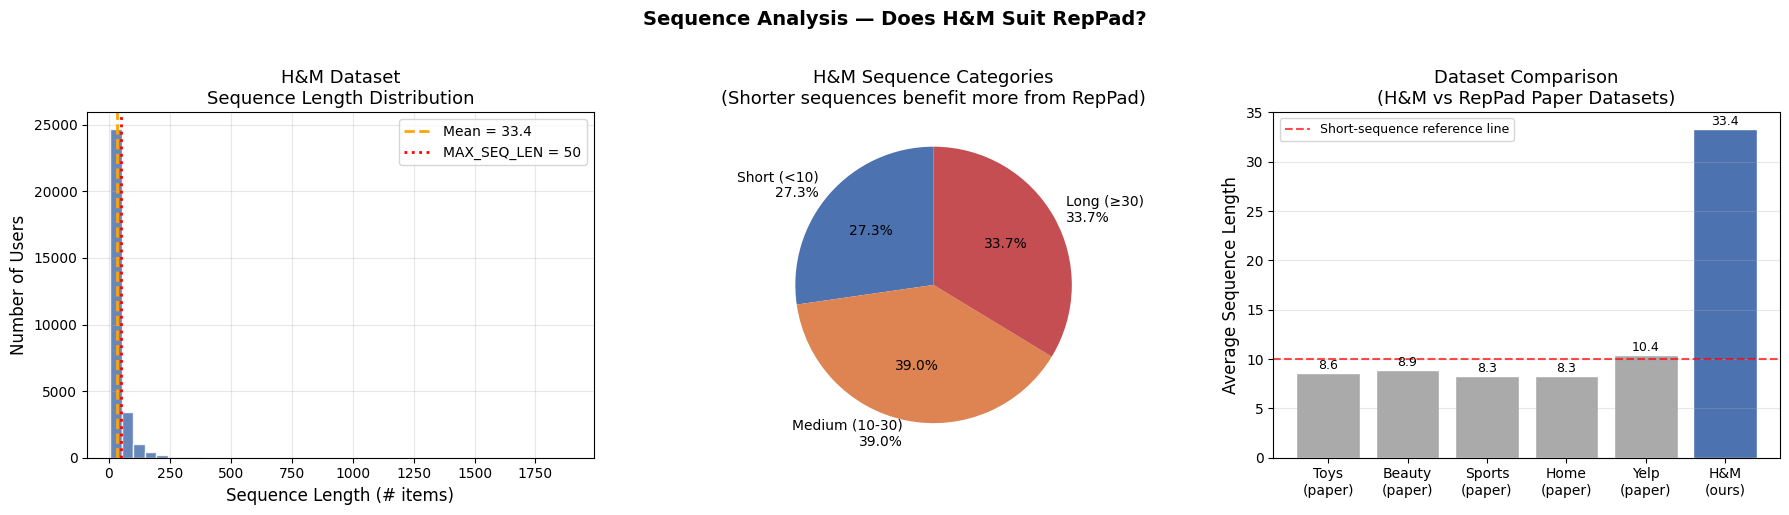

Saved: /kaggle/working/sequence_analysis_hm.png


In [9]:
# ── Sequence Analysis for H&M Dataset ────────────────────────────────────────

import numpy as np
import matplotlib.pyplot as plt
import os

# Make sure user_sequences already exists:
# user_sequences = df_sorted.groupby('user_id')['item_id'].apply(list).to_dict()

seq_lengths = [len(seq) for seq in user_sequences.values()]
total = len(seq_lengths)

# ── Basic statistics ─────────────────────────────────────────────────────────
print('=== H&M Sequence Length Statistics ===')
print(f'Total users : {total:,}')
print(f'Min         : {min(seq_lengths)}')
print(f'Max         : {max(seq_lengths)}')
print(f'Mean        : {np.mean(seq_lengths):.1f}')
print(f'Median      : {np.median(seq_lengths):.1f}')
print(f'Std         : {np.std(seq_lengths):.1f}')

# ── Categories ───────────────────────────────────────────────────────────────
short = sum(1 for l in seq_lengths if l < 10)
medium = sum(1 for l in seq_lengths if 10 <= l < 30)
long_ = sum(1 for l in seq_lengths if l >= 30)

print('\n=== Sequence Categories ===')
print(f'Short  (<10 items)   : {short:,} ({short/total*100:.1f}%)')
print(f'Medium (10-30 items) : {medium:,} ({medium/total*100:.1f}%)')
print(f'Long   (>=30 items)  : {long_:,} ({long_/total*100:.1f}%)')

# ── RepPad feasibility check ─────────────────────────────────────────────────
MAX_SEQ_LEN = 50

can_reppad = sum(1 for l in seq_lengths if int(MAX_SEQ_LEN / (l + 1)) > 1)

print('\n=== RepPad Feasibility ===')
print(f'Users that can benefit from RepPad with MAX_SEQ_LEN={MAX_SEQ_LEN}: '
      f'{can_reppad:,} ({can_reppad/total*100:.1f}%)')

# ── Sequence length visualisation ────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Distribution histogram
axes[0].hist(seq_lengths, bins=40, color='#4C72B0', edgecolor='white', alpha=0.85)
axes[0].axvline(x=np.mean(seq_lengths), color='orange', linestyle='--',
                linewidth=2, label=f'Mean = {np.mean(seq_lengths):.1f}')
axes[0].axvline(x=MAX_SEQ_LEN, color='red', linestyle=':',
                linewidth=2, label=f'MAX_SEQ_LEN = {MAX_SEQ_LEN}')
axes[0].set_xlabel('Sequence Length (# items)', fontsize=12)
axes[0].set_ylabel('Number of Users', fontsize=12)
axes[0].set_title('H&M Dataset\nSequence Length Distribution', fontsize=13)
axes[0].legend(fontsize=10)
axes[0].grid(alpha=0.3)

# Plot 2: Category pie chart
axes[1].pie(
    [short, medium, long_],
    labels=[
        f'Short (<10)\n{short/total*100:.1f}%',
        f'Medium (10-30)\n{medium/total*100:.1f}%',
        f'Long (≥30)\n{long_/total*100:.1f}%'
    ],
    colors=['#4C72B0', '#DD8452', '#C44E52'],
    autopct='%1.1f%%',
    startangle=90,
    textprops={'fontsize': 10}
)
axes[1].set_title('H&M Sequence Categories\n(Shorter sequences benefit more from RepPad)',
                  fontsize=13)

# Plot 3: Comparison with paper datasets + H&M
datasets = [
    'Toys\n(paper)',
    'Beauty\n(paper)',
    'Sports\n(paper)',
    'Home\n(paper)',
    'Yelp\n(paper)',
    'H&M\n(ours)'
]

avg_lengths = [
    8.6,                  # Toys
    8.9,                  # Beauty
    8.3,                  # Sports
    8.3,                  # Home
    10.4,                 # Yelp
    np.mean(seq_lengths)  # H&M
]

bar_colors = ['#aaaaaa'] * 5 + ['#4C72B0']

bars = axes[2].bar(datasets, avg_lengths, color=bar_colors, edgecolor='white')
axes[2].axhline(y=10, color='red', linestyle='--', alpha=0.7,
                label='Short-sequence reference line')

for bar, val in zip(bars, avg_lengths):
    axes[2].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.1,
        f'{val:.1f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

axes[2].set_ylabel('Average Sequence Length', fontsize=12)
axes[2].set_title('Dataset Comparison\n(H&M vs RepPad Paper Datasets)', fontsize=13)
axes[2].legend(fontsize=9)
axes[2].grid(axis='y', alpha=0.3)

plt.suptitle('Sequence Analysis — Does H&M Suit RepPad?',
             fontsize=14, y=1.02, fontweight='bold')

plt.tight_layout()

save_path = os.path.join(OUTPUT_PATH, 'sequence_analysis_hm.png')
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()

print(f'Saved: {save_path}')

## 4. RepPad Data Augmentation

Exact implementation of **Algorithm 1** from the paper (`m = random(1, max)` variant — best performing).

In [9]:
def seq_prepare(seq, max_len):
    """
    Eq. (2) from the paper:
      - Intercept the most recent max_len items if len > max_len
      - Zero-pad on the left if len < max_len
    """
    seq = seq[-max_len:]
    pad_len = max_len - len(seq)
    return [0] * pad_len + seq

def reppad(orig_seq, max_len, use_delimiter=True):
    """
    RepPad — Algorithm 1, m = random(1, max) with delimiter 0.
    Best performing variant per paper Section 3.8 ablation study.
    use_delimiter=True  → recommended for Transformer-based models (SASRec)
    use_delimiter=False → recommended for RNN-based models (GRU4Rec)
    """
    train_items  = orig_seq[:-3] if len(orig_seq) > 3 else orig_seq[:-2]
    target_items = orig_seq[1:-2] if len(orig_seq) > 3 else orig_seq[1:-1]

    if len(train_items) == 0:
        return seq_prepare([], max_len), seq_prepare([], max_len)

    unit_len = len(train_items) + (1 if use_delimiter else 0)
    if int(max_len / unit_len) <= 1:
        return seq_prepare(train_items, max_len), seq_prepare(target_items, max_len)

    max_pad_num = int(max_len / unit_len)
    pad_num     = random.randint(1, max_pad_num)    # m ~ Uniform(1, max)

    final_input  = list(train_items)
    final_target = list(target_items)

    for _ in range(pad_num):
        if use_delimiter:
            final_input  = list(train_items)  + [0] + final_input
            final_target = list(target_items) + [0] + final_target
        else:
            final_input  = list(train_items)  + final_input
            final_target = list(target_items) + final_target

    return seq_prepare(final_input, max_len), seq_prepare(final_target, max_len)

# ── Sanity check ──────────────────────────────────────────────────────────────
example_seq = [1, 2, 3, 4, 5, 6]
inp, tgt = reppad(example_seq, max_len=20)
print('Input  :', inp)
print('Target :', tgt)
print('Lengths:', len(inp), len(tgt))

Input  : [0, 0, 0, 0, 0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3]
Target : [0, 0, 0, 0, 0, 2, 3, 4, 0, 2, 3, 4, 0, 2, 3, 4, 0, 2, 3, 4]
Lengths: 20 20


In [10]:
# ── PyTorch Dataset wrappers ──────────────────────────────────────────────────
class TrainDataset(Dataset):
    """
    Training dataset. RepPad is applied on-the-fly in __getitem__ so
    each epoch samples a different random padding count m.
    Per paper Section 3.8: use_delimiter=False for GRU4Rec, True for SASRec.
    """
    def __init__(self, user_sequences, max_len, use_reppad=True, use_delimiter=True):
        self.user_ids    = list(user_sequences.keys())
        self.sequences   = user_sequences
        self.max_len     = max_len
        self.use_reppad  = use_reppad
        self.use_delim   = use_delimiter

    def __len__(self):
        return len(self.user_ids)

    def __getitem__(self, idx):
        uid  = self.user_ids[idx]
        seq  = self.sequences[uid]
        if self.use_reppad:
            inp, tgt = reppad(seq, self.max_len, use_delimiter=self.use_delim)
        else:
            train_items  = seq[:-3] if len(seq) > 3 else seq[:-2]
            target_items = seq[1:-2] if len(seq) > 3 else seq[1:-1]
            inp = seq_prepare(train_items,  self.max_len)
            tgt = seq_prepare(target_items, self.max_len)
        return (
            torch.tensor(inp, dtype=torch.long),
            torch.tensor(tgt, dtype=torch.long)
        )


class EvalDataset(Dataset):
    """
    Evaluation dataset. Returns the input sequence and the single target item.
    Uses leave-one-out strategy matching paper Section 3.4.
    """
    def __init__(self, eval_dict, max_len):
        self.data    = list(eval_dict.items())
        self.max_len = max_len

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        uid, (history, target) = self.data[idx]
        inp = seq_prepare(history, self.max_len)
        return (
            torch.tensor(inp,    dtype=torch.long),
            torch.tensor(target, dtype=torch.long)
        )

## 5. Model Definitions

Self-contained implementations of **GRU4Rec** and **SASRec** (matching the paper's baselines). The RepPad augmentation is handled entirely by the Dataset, so these models are unchanged.

In [11]:
# ── GRU4Rec ───────────────────────────────────────────────────────────────────
class GRU4Rec(nn.Module):
    def __init__(self, num_items, embed_dim, hidden_dim=128, num_layers=1, dropout=0.2):
        super().__init__()
        self.item_emb = nn.Embedding(num_items + 1, embed_dim, padding_idx=0)
        self.gru = nn.GRU(embed_dim, hidden_dim, num_layers=num_layers,
                          batch_first=True,
                          dropout=dropout if num_layers > 1 else 0.0)
        self.dropout  = nn.Dropout(dropout)
        self.out_proj = nn.Linear(hidden_dim, num_items + 1)
        self._init_weights()

    def _init_weights(self):
        nn.init.normal_(self.item_emb.weight, std=0.01)
        for name, param in self.gru.named_parameters():
            if 'weight' in name:
                nn.init.xavier_uniform_(param)

    def forward(self, input_seq):
        emb = self.dropout(self.item_emb(input_seq))
        out, _ = self.gru(emb)
        return self.out_proj(self.dropout(out))   # (B, L, num_items+1)


# ── SASRec ────────────────────────────────────────────────────────────────────
class SelfAttentionBlock(nn.Module):
    def __init__(self, embed_dim, num_heads, dropout):
        super().__init__()
        self.attn = nn.MultiheadAttention(embed_dim, num_heads,
                                           dropout=dropout, batch_first=True)
        self.ff   = nn.Sequential(
            nn.Linear(embed_dim, embed_dim * 4),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(embed_dim * 4, embed_dim),
        )
        self.ln1     = nn.LayerNorm(embed_dim)
        self.ln2     = nn.LayerNorm(embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, attn_mask=None, key_padding_mask=None):
        res = x
        x   = self.ln1(x)
        x, _ = self.attn(x, x, x, attn_mask=attn_mask,
                         key_padding_mask=key_padding_mask,
                         need_weights=False)
        x = self.dropout(x) + res
        res = x
        x   = self.ln2(x)
        return self.ff(x) + res


class SASRec(nn.Module):
    def __init__(self, num_items, embed_dim, max_len,
                 num_heads=1, num_layers=2, dropout=0.2):
        super().__init__()
        self.item_emb = nn.Embedding(num_items + 1, embed_dim, padding_idx=0)
        self.pos_emb  = nn.Embedding(max_len + 1,   embed_dim)
        self.dropout  = nn.Dropout(dropout)
        self.blocks   = nn.ModuleList([
            SelfAttentionBlock(embed_dim, num_heads, dropout)
            for _ in range(num_layers)
        ])
        self.ln       = nn.LayerNorm(embed_dim)
        self.out_proj = nn.Linear(embed_dim, num_items + 1)
        self.max_len  = max_len
        self._init_weights()

    def _init_weights(self):
        nn.init.normal_(self.item_emb.weight, std=0.01)
        nn.init.normal_(self.pos_emb.weight,  std=0.01)
        for p in self.parameters():
            if p.dim() > 1:
                nn.init.xavier_uniform_(p)

    def forward(self, input_seq):
        B, L = input_seq.shape
        positions = torch.arange(1, L + 1, device=input_seq.device).unsqueeze(0)
        x = self.dropout(self.item_emb(input_seq) + self.pos_emb(positions))

        # ── Float causal mask — prevents NaN in softmax ───────────────────────
        # Using -inf for masked positions instead of bool so softmax
        # never receives an all-masked row (which produces NaN).
        causal_mask = torch.zeros(L, L, device=x.device)
        causal_mask = causal_mask.masked_fill(
            torch.triu(torch.ones(L, L, device=x.device, dtype=torch.bool),
                       diagonal=1),
            float('-inf')
        )

        key_pad_mask = (input_seq == 0)   # (B, L)

        for block in self.blocks:
            x = block(x, attn_mask=causal_mask, key_padding_mask=key_pad_mask)

        return self.out_proj(self.ln(x))   # (B, L, num_items+1)


print('Models ready.')

Models ready.


## 6. Training & Evaluation Utilities

In [12]:
# ── Fast batched evaluation ───────────────────────────────────────────────────
EVAL_USERS = 2000   # evaluate on a random subset — fast and statistically valid

@torch.no_grad()
def evaluate(model, eval_loader, num_items, top_k_list, device, num_neg=100, use_amp=True):
    model.eval()
    metrics = {f'HR@{k}': [] for k in top_k_list}
    metrics.update({f'NDCG@{k}': [] for k in top_k_list})

    evaluated = 0
    for inp, targets in eval_loader:
        if evaluated >= EVAL_USERS:
            break

        inp     = inp.to(device)
        targets = targets.to(device)
        B       = inp.size(0)

        if use_amp:
            with torch.amp.autocast('cuda'):
                logits = model(inp)
        else:
            logits = model(inp)               # full fp32 for SASRec

        last_logits = logits[:, -1, :]        # (B, V)

        # Build candidate matrix — target always at column 0
        C = num_neg + 1
        cand_matrix = torch.zeros(B, C, dtype=torch.long, device=device)
        cand_matrix[:, 0] = targets

        for i in range(B):
            t    = targets[i].item()
            negs = random.sample(range(1, num_items + 1), num_neg + 1)
            negs = [x for x in negs if x != t][:num_neg]
            cand_matrix[i, 1:] = torch.tensor(negs, dtype=torch.long, device=device)

        # Gather scores and rank
        scores = torch.gather(last_logits, 1, cand_matrix)   # (B, C)
        ranked = scores.argsort(dim=1, descending=True)       # (B, C)

        for i in range(B):
            rank_of_target = (ranked[i] == 0).nonzero(as_tuple=True)[0].item()
            for k in top_k_list:
                metrics[f'HR@{k}'].append(int(rank_of_target < k))
                metrics[f'NDCG@{k}'].append(
                    1.0 / math.log2(rank_of_target + 2) if rank_of_target < k else 0.0
                )

        evaluated += B

    return {key: np.mean(vals) for key, vals in metrics.items()}


# ── Training loop ─────────────────────────────────────────────────────────────
def train_model(model, train_loader, val_loader, test_loader,
                num_items, top_k_list, device,
                num_epochs=200, lr=0.001, patience=20,
                model_name='Model', use_amp=True):
    """
    use_amp=True  → GRU4Rec  (mixed precision, faster)
    use_amp=False → SASRec   (full fp32, prevents NaN in attention)
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, betas=(0.9, 0.999))
    criterion = nn.CrossEntropyLoss(ignore_index=0)
    scaler    = torch.amp.GradScaler('cuda') if use_amp else None

    best_val_ndcg     = -1
    best_test_metrics = None
    no_improve        = 0
    train_losses      = []

    for epoch in range(1, num_epochs + 1):
        model.train()
        epoch_loss  = 0.0
        valid_batch = 0
        t0 = time.time()

        for inp, tgt in train_loader:
            inp = inp.to(device)
            tgt = tgt.to(device)
            optimizer.zero_grad()

            if use_amp:
                with torch.amp.autocast('cuda'):
                    logits = model(inp)
                    B, L, V = logits.shape
                    loss = criterion(logits.view(B * L, V), tgt.view(B * L))
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                scaler.step(optimizer)
                scaler.update()
            else:
                logits = model(inp)
                B, L, V = logits.shape
                loss = criterion(logits.view(B * L, V), tgt.view(B * L))
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                optimizer.step()

            # Skip NaN batches gracefully
            if torch.isnan(loss):
                optimizer.zero_grad()
                continue

            epoch_loss  += loss.item()
            valid_batch += 1

        avg_loss = epoch_loss / max(valid_batch, 1)
        train_losses.append(avg_loss)
        torch.cuda.empty_cache()

        val_metrics = evaluate(model, val_loader, num_items,
                               top_k_list, device, NUM_NEG, use_amp=use_amp)
        val_ndcg    = val_metrics[f'NDCG@{top_k_list[1]}']
        elapsed     = time.time() - t0

        if epoch % 5 == 0 or epoch == 1:
            print(f'[{model_name}] Epoch {epoch:3d}/{num_epochs} | '
                  f'Loss: {avg_loss:.4f} | '
                  f'Val NDCG@{top_k_list[1]}: {val_ndcg:.4f} | '
                  f'Time: {elapsed:.1f}s')

        if val_ndcg > best_val_ndcg:
            best_val_ndcg     = val_ndcg
            best_test_metrics = evaluate(model, test_loader, num_items,
                                         top_k_list, device, NUM_NEG, use_amp=use_amp)
            torch.save(model.state_dict(),
                       os.path.join(OUTPUT_PATH, f'{model_name}_best.pt'))
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f'Early stopping at epoch {epoch}')
                break

    return best_test_metrics, train_losses

print('Utilities ready.')

Utilities ready.


## 7. Run Experiments

In [13]:
# ── Build DataLoaders ─────────────────────────────────────────────────────────
# Per paper Section 3.8 ablation study:
# GRU4Rec  → use_delimiter=False (better performance without delimiter)
# SASRec   → use_delimiter=True  (better performance with delimiter)

# No RepPad — shared baseline loader for both models
train_dataset_no = TrainDataset(user_sequences, MAX_SEQ_LEN,
                                use_reppad=False)

# RepPad for GRU4Rec — no delimiter
train_dataset_rp_gru = TrainDataset(user_sequences, MAX_SEQ_LEN,
                                     use_reppad=True, use_delimiter=False)

# RepPad for SASRec — with delimiter
train_dataset_rp_sas = TrainDataset(user_sequences, MAX_SEQ_LEN,
                                     use_reppad=True, use_delimiter=True)

# Evaluation datasets
val_dataset  = EvalDataset(val_seqs,  MAX_SEQ_LEN)
test_dataset = EvalDataset(test_seqs, MAX_SEQ_LEN)

loader_kwargs = dict(batch_size=BATCH_SIZE, num_workers=2, pin_memory=True)

train_loader_no      = DataLoader(train_dataset_no,      shuffle=True,  **loader_kwargs)
train_loader_rp_gru  = DataLoader(train_dataset_rp_gru,  shuffle=True,  **loader_kwargs)
train_loader_rp_sas  = DataLoader(train_dataset_rp_sas,  shuffle=True,  **loader_kwargs)
val_loader           = DataLoader(val_dataset,            shuffle=False, **loader_kwargs)
test_loader          = DataLoader(test_dataset,           shuffle=False, **loader_kwargs)

print(f'Train batches (no RepPad) : {len(train_loader_no)}')
print(f'Train batches (GRU RepPad): {len(train_loader_rp_gru)}')
print(f'Train batches (SAS RepPad): {len(train_loader_rp_sas)}')
print(f'Val  batches              : {len(val_loader)}')
print(f'Test batches              : {len(test_loader)}')

Train batches (no RepPad) : 469
Train batches (GRU RepPad): 469
Train batches (SAS RepPad): 469
Val  batches              : 469
Test batches              : 469


In [14]:
# ── GPU memory reset before experiments ──────────────────────────────────────
import gc
gc.collect()
torch.cuda.empty_cache()
print(f'GPU free: {torch.cuda.mem_get_info()[0]/1e9:.2f} GB')

GPU free: 15.53 GB


In [18]:
# ════════════════════════════════════════════════════════════════════════════════
#  Experiment 1 — GRU4Rec  (baseline, no RepPad)
# ════════════════════════════════════════════════════════════════════════════════
print('=' * 60)
print('Experiment 1: GRU4Rec — Baseline (No RepPad)')
print('=' * 60)

gru_baseline = GRU4Rec(NUM_ITEMS, EMBED_DIM).to(DEVICE)

gru_base_metrics, gru_base_losses = train_model(
    gru_baseline, train_loader_no, val_loader, test_loader,
    NUM_ITEMS, TOP_K, DEVICE,
    num_epochs=NUM_EPOCHS, lr=LR, patience=PATIENCE,
    model_name='GRU4Rec_Baseline',
    use_amp=True        # GRU4Rec — mixed precision safe
)

print('\n--- GRU4Rec Baseline Test Results ---')
for k, v in gru_base_metrics.items():
    print(f'  {k}: {v:.4f}')

Experiment 1: GRU4Rec — Baseline (No RepPad)
[GRU4Rec_Baseline] Epoch   1/200 | Loss: 10.4381 | Val NDCG@10: 0.3518 | Time: 34.6s
[GRU4Rec_Baseline] Epoch   5/200 | Loss: 9.0161 | Val NDCG@10: 0.5147 | Time: 34.6s
[GRU4Rec_Baseline] Epoch  10/200 | Loss: 7.6967 | Val NDCG@10: 0.5336 | Time: 34.7s
[GRU4Rec_Baseline] Epoch  15/200 | Loss: 6.7529 | Val NDCG@10: 0.5346 | Time: 34.7s
[GRU4Rec_Baseline] Epoch  20/200 | Loss: 6.1258 | Val NDCG@10: 0.5262 | Time: 34.6s
[GRU4Rec_Baseline] Epoch  25/200 | Loss: 5.7013 | Val NDCG@10: 0.5216 | Time: 34.4s
[GRU4Rec_Baseline] Epoch  30/200 | Loss: 5.4080 | Val NDCG@10: 0.5174 | Time: 34.2s
Early stopping at epoch 32

--- GRU4Rec Baseline Test Results ---
  HR@5: 0.6270
  HR@10: 0.7495
  HR@20: 0.8584
  NDCG@5: 0.4902
  NDCG@10: 0.5299
  NDCG@20: 0.5575


In [19]:
# ── Save GRU4Rec Baseline model & results ────────────────────────────────────
import json

# Save model weights
gru_base_path = os.path.join(OUTPUT_PATH, 'GRU4Rec_Baseline_final.pt')
torch.save({
    'model_state_dict' : gru_baseline.state_dict(),
    'num_items'        : NUM_ITEMS,
    'embed_dim'        : EMBED_DIM,
    'model_name'       : 'GRU4Rec_Baseline',
}, gru_base_path)

# Save metrics to JSON
gru_base_json = os.path.join(OUTPUT_PATH, 'GRU4Rec_Baseline_metrics.json')
with open(gru_base_json, 'w') as f:
    json.dump(gru_base_metrics, f, indent=2)

print(f'Model   saved → {gru_base_path}')
print(f'Metrics saved → {gru_base_json}')
print('\nGRU4Rec Baseline — Test Metrics:')
for k, v in gru_base_metrics.items():
    print(f'  {k}: {v:.4f}')

Model   saved → /kaggle/working/GRU4Rec_Baseline_final.pt
Metrics saved → /kaggle/working/GRU4Rec_Baseline_metrics.json

GRU4Rec Baseline — Test Metrics:
  HR@5: 0.6270
  HR@10: 0.7495
  HR@20: 0.8584
  NDCG@5: 0.4902
  NDCG@10: 0.5299
  NDCG@20: 0.5575


In [20]:
# ════════════════════════════════════════════════════════════════════════════════
#  Experiment 2 — GRU4Rec + RepPad
# ════════════════════════════════════════════════════════════════════════════════
print('=' * 60)
print('Experiment 2: GRU4Rec — with RepPad')
print('=' * 60)

gru_reppad = GRU4Rec(NUM_ITEMS, EMBED_DIM).to(DEVICE)

gru_rp_metrics, gru_rp_losses = train_model(
    gru_reppad, train_loader_rp_gru, val_loader, test_loader,  # ← no delimiter loader
    NUM_ITEMS, TOP_K, DEVICE,
    num_epochs=NUM_EPOCHS, lr=LR, patience=PATIENCE,
    model_name='GRU4Rec_RepPad',
    use_amp=True        # GRU4Rec — mixed precision safe
)

print('\n--- GRU4Rec + RepPad Test Results ---')
for k, v in gru_rp_metrics.items():
    print(f'  {k}: {v:.4f}')

Experiment 2: GRU4Rec — with RepPad
[GRU4Rec_RepPad] Epoch   1/200 | Loss: 10.4454 | Val NDCG@10: 0.3494 | Time: 34.5s
[GRU4Rec_RepPad] Epoch   5/200 | Loss: 9.0460 | Val NDCG@10: 0.4854 | Time: 34.5s
[GRU4Rec_RepPad] Epoch  10/200 | Loss: 7.3640 | Val NDCG@10: 0.5130 | Time: 34.4s
[GRU4Rec_RepPad] Epoch  15/200 | Loss: 6.1695 | Val NDCG@10: 0.5046 | Time: 34.4s
[GRU4Rec_RepPad] Epoch  20/200 | Loss: 5.4081 | Val NDCG@10: 0.5026 | Time: 34.4s
[GRU4Rec_RepPad] Epoch  25/200 | Loss: 4.9369 | Val NDCG@10: 0.5007 | Time: 34.4s
Early stopping at epoch 28

--- GRU4Rec + RepPad Test Results ---
  HR@5: 0.5913
  HR@10: 0.7246
  HR@20: 0.8472
  NDCG@5: 0.4543
  NDCG@10: 0.4978
  NDCG@20: 0.5289


In [21]:
# ════════════════════════════════════════════════════════════════════════════════
#  Experiment 3 — SASRec (baseline, no RepPad)
# ════════════════════════════════════════════════════════════════════════════════
print('=' * 60)
print('Experiment 3: SASRec — Baseline (No RepPad)')
print('=' * 60)

# Clear GPU memory before loading new model
import gc
gc.collect()
torch.cuda.empty_cache()

sas_baseline = SASRec(
    NUM_ITEMS, EMBED_DIM, MAX_SEQ_LEN,
    num_heads=1, num_layers=2
).to(DEVICE)

sas_base_metrics, sas_base_losses = train_model(
    sas_baseline, train_loader_no, val_loader, test_loader,
    NUM_ITEMS, TOP_K, DEVICE,
    num_epochs=NUM_EPOCHS, lr=LR, patience=PATIENCE,
    model_name='SASRec_Baseline',
    use_amp=False        # fp32 for SASRec — prevents NaN in attention
)

print('\n--- SASRec Baseline Test Results ---')
for k, v in sas_base_metrics.items():
    print(f'  {k}: {v:.4f}')

Experiment 3: SASRec — Baseline (No RepPad)
[SASRec_Baseline] Epoch   1/200 | Loss: 10.4263 | Val NDCG@10: 0.3573 | Time: 44.9s
[SASRec_Baseline] Epoch   5/200 | Loss: 8.8827 | Val NDCG@10: 0.5361 | Time: 45.0s
[SASRec_Baseline] Epoch  10/200 | Loss: 7.4860 | Val NDCG@10: 0.5483 | Time: 45.1s
[SASRec_Baseline] Epoch  15/200 | Loss: 6.4166 | Val NDCG@10: 0.5362 | Time: 45.2s
[SASRec_Baseline] Epoch  20/200 | Loss: 5.7804 | Val NDCG@10: 0.5401 | Time: 45.1s
[SASRec_Baseline] Epoch  25/200 | Loss: 5.3929 | Val NDCG@10: 0.5296 | Time: 45.4s
Early stopping at epoch 27

--- SASRec Baseline Test Results ---
  HR@5: 0.6558
  HR@10: 0.7773
  HR@20: 0.8779
  NDCG@5: 0.5132
  NDCG@10: 0.5524
  NDCG@20: 0.5779


In [22]:
# ════════════════════════════════════════════════════════════════════════════════
#  Experiment 4 — SASRec + RepPad
# ════════════════════════════════════════════════════════════════════════════════
print('=' * 60)
print('Experiment 4: SASRec — with RepPad')
print('=' * 60)

# Clear GPU memory before loading new model
import gc
gc.collect()
torch.cuda.empty_cache()

sas_reppad = SASRec(
    NUM_ITEMS, EMBED_DIM, MAX_SEQ_LEN,
    num_heads=1, num_layers=2
).to(DEVICE)

sas_rp_metrics, sas_rp_losses = train_model(
    sas_reppad, train_loader_rp_sas, val_loader, test_loader,  # ← with delimiter loader
    NUM_ITEMS, TOP_K, DEVICE,
    num_epochs=NUM_EPOCHS, lr=LR, patience=PATIENCE,
    model_name='SASRec_RepPad',
    use_amp=False        # fp32 for SASRec — prevents NaN in attention
)

print('\n--- SASRec + RepPad Test Results ---')
for k, v in sas_rp_metrics.items():
    print(f'  {k}: {v:.4f}')

Experiment 4: SASRec — with RepPad
[SASRec_RepPad] Epoch   1/200 | Loss: 10.4243 | Val NDCG@10: 0.3496 | Time: 45.8s
[SASRec_RepPad] Epoch   5/200 | Loss: 8.7522 | Val NDCG@10: 0.5214 | Time: 46.0s
[SASRec_RepPad] Epoch  10/200 | Loss: 6.7494 | Val NDCG@10: 0.5370 | Time: 46.1s
[SASRec_RepPad] Epoch  15/200 | Loss: 5.5820 | Val NDCG@10: 0.5195 | Time: 46.0s
[SASRec_RepPad] Epoch  20/200 | Loss: 5.0051 | Val NDCG@10: 0.5156 | Time: 46.1s
[SASRec_RepPad] Epoch  25/200 | Loss: 4.6232 | Val NDCG@10: 0.5176 | Time: 46.4s
Early stopping at epoch 27

--- SASRec + RepPad Test Results ---
  HR@5: 0.6392
  HR@10: 0.7686
  HR@20: 0.8701
  NDCG@5: 0.4969
  NDCG@10: 0.5387
  NDCG@20: 0.5645


## 8. Results Summary & Visualisation

In [31]:
import matplotlib.pyplot as plt

# ── Tabular comparison ────────────────────────────────────────────────────────
results = {
    'GRU4Rec':          gru_base_metrics,
    'GRU4Rec + RepPad': gru_rp_metrics,
    'SASRec':           sas_base_metrics,
    'SASRec + RepPad':  sas_rp_metrics,
}

rows = []
for model_label, metrics in results.items():
    row = {'Model': model_label}
    row.update(metrics)
    rows.append(row)

results_df = pd.DataFrame(rows).set_index('Model')

# Improvement percentages
print('=== RepPad Improvement over Baseline ===')
for k in TOP_K:
    for metric in [f'HR@{k}', f'NDCG@{k}']:
        base_gru = results_df.loc['GRU4Rec', metric]
        rp_gru   = results_df.loc['GRU4Rec + RepPad', metric]
        base_sas = results_df.loc['SASRec', metric]
        rp_sas   = results_df.loc['SASRec + RepPad', metric]
        print(f'{metric}  |  '
              f'GRU4Rec improvement: {(rp_gru-base_gru)/base_gru*100:+.1f}%  |  '
              f'SASRec improvement:  {(rp_sas-base_sas)/base_sas*100:+.1f}%')

print('\n=== Full Results Table ===')
print(results_df.round(4).to_string())

=== RepPad Improvement over Baseline ===
HR@5  |  GRU4Rec improvement: -2.8%  |  SASRec improvement:  -0.2%
NDCG@5  |  GRU4Rec improvement: -4.9%  |  SASRec improvement:  -2.1%
HR@10  |  GRU4Rec improvement: -3.2%  |  SASRec improvement:  -0.3%
NDCG@10  |  GRU4Rec improvement: -4.9%  |  SASRec improvement:  -2.1%
HR@20  |  GRU4Rec improvement: -2.6%  |  SASRec improvement:  -0.2%
NDCG@20  |  GRU4Rec improvement: -4.6%  |  SASRec improvement:  -2.0%

=== Full Results Table ===
                    HR@5   HR@10   HR@20  NDCG@5  NDCG@10  NDCG@20
Model                                                             
GRU4Rec           0.6304  0.7573  0.8652  0.4965   0.5372   0.5647
GRU4Rec + RepPad  0.6128  0.7329  0.8428  0.4721   0.5111   0.5389
SASRec            0.6338  0.7603  0.8608  0.5086   0.5500   0.5754
SASRec + RepPad   0.6328  0.7578  0.8589  0.4979   0.5382   0.5640


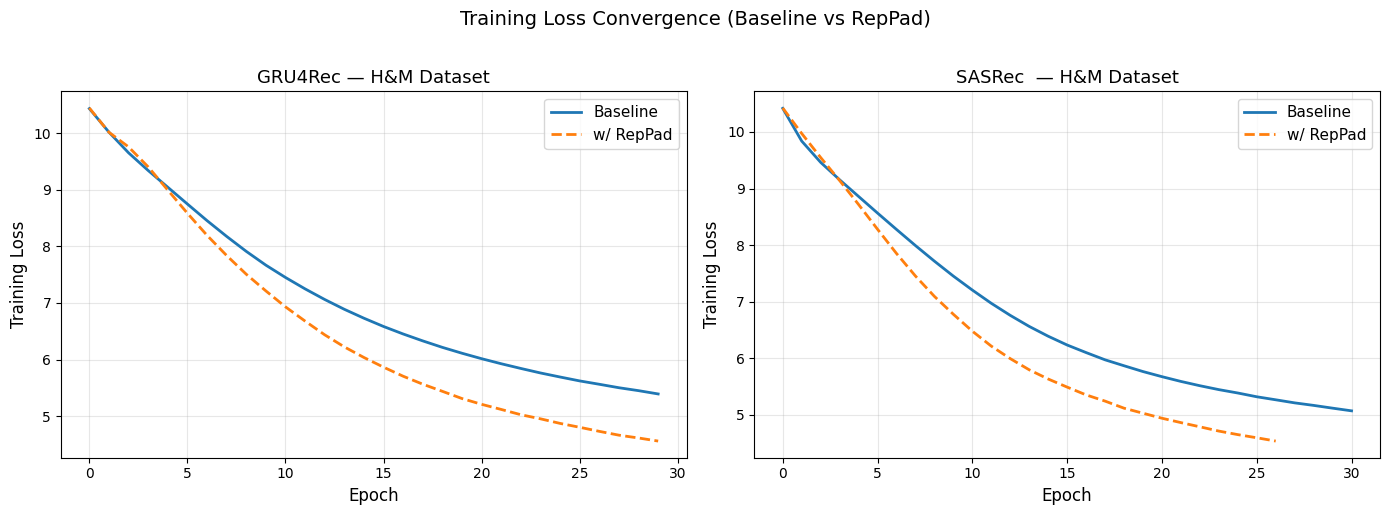

Saved: loss_convergence.png


In [32]:
# ── Loss convergence plot (Figure 3 equivalent from the paper) ────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (base_losses, rp_losses, title) in zip(
    axes,
    [
        (gru_base_losses, gru_rp_losses, 'GRU4Rec — H&M Dataset'),
        (sas_base_losses, sas_rp_losses, 'SASRec  — H&M Dataset'),
    ]
):
    ax.plot(base_losses, label='Baseline', linewidth=2)
    ax.plot(rp_losses,   label='w/ RepPad', linewidth=2, linestyle='--')
    ax.set_xlabel('Epoch', fontsize=12)
    ax.set_ylabel('Training Loss', fontsize=12)
    ax.set_title(title, fontsize=13)
    ax.legend(fontsize=11)
    ax.grid(alpha=0.3)

plt.suptitle('Training Loss Convergence (Baseline vs RepPad)', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PATH, 'loss_convergence.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: loss_convergence.png')

/tmp/ipykernel_57/2088596841.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(model_labels, rotation=15, ha='right')
/tmp/ipykernel_57/2088596841.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(model_labels, rotation=15, ha='right')


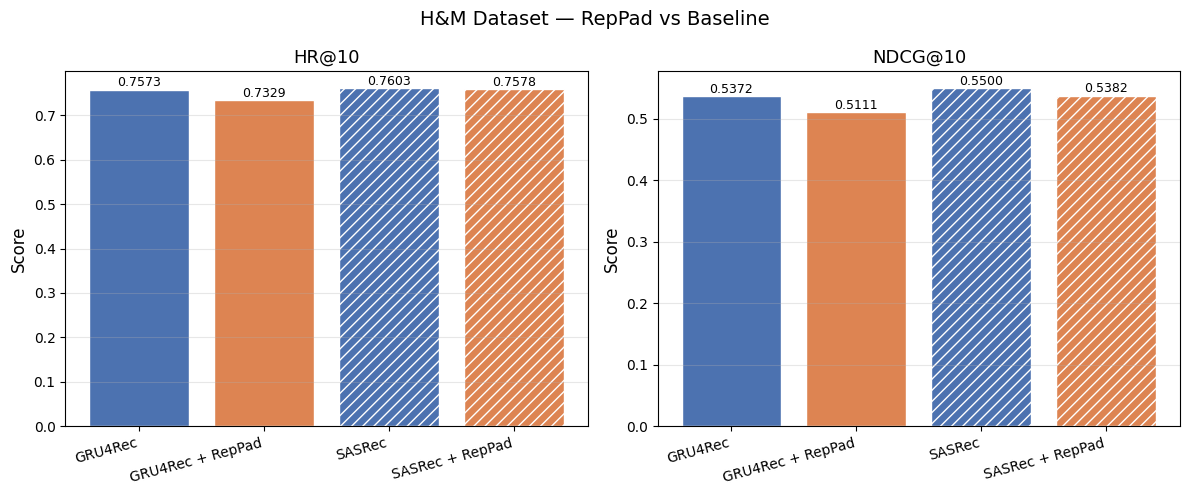

Saved: metric_comparison.png


In [33]:
# ── Bar chart — HR@10 and NDCG@10 ────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
model_labels = list(results.keys())
colors  = ['#4C72B0', '#DD8452', '#4C72B0', '#DD8452']
hatches = ['', '', '///', '///']

for ax, metric in zip(axes, ['HR@10', 'NDCG@10']):
    vals = [results[m][metric] for m in model_labels]
    bars = ax.bar(model_labels, vals, color=colors, hatch=hatches, edgecolor='white')
    ax.set_title(metric, fontsize=13)
    ax.set_ylabel('Score', fontsize=12)
    ax.set_xticklabels(model_labels, rotation=15, ha='right')
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
                f'{val:.4f}', ha='center', va='bottom', fontsize=9)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('H&M Dataset — RepPad vs Baseline', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PATH, 'metric_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: metric_comparison.png')

In [34]:
# ── Save full results table to CSV ────────────────────────────────────────────
csv_path = os.path.join(OUTPUT_PATH, 'reppad_hm_results.csv')
results_df.to_csv(csv_path)
print(f'Results saved to {csv_path}')
print('\nFinal Results:')
print(results_df.round(4).to_string())

Results saved to /kaggle/working/reppad_hm_results.csv

Final Results:
                    HR@5   HR@10   HR@20  NDCG@5  NDCG@10  NDCG@20
Model                                                             
GRU4Rec           0.6304  0.7573  0.8652  0.4965   0.5372   0.5647
GRU4Rec + RepPad  0.6128  0.7329  0.8428  0.4721   0.5111   0.5389
SASRec            0.6338  0.7603  0.8608  0.5086   0.5500   0.5754
SASRec + RepPad   0.6328  0.7578  0.8589  0.4979   0.5382   0.5640


## 9. RepPad Ablation — Variant Comparison

Reproducing Table 8 / Figure 2 from the paper: comparing `RP-Fix`, `RP-Max`, `RP(0,Max)`, and `RP(1,Max)` on SASRec.

In [35]:
def reppad_variant(orig_seq, max_len, variant='rp_1_max', use_delimiter=True):
    """
    Table 1 from the paper — RepPad variant options:
      'none'     — no RepPad (standard zero padding)
      'rp_fix'   — fixed m=2
      'rp_max'   — always use maximum m
      'rp_0_max' — m ~ Uniform(0, max)
      'rp_1_max' — m ~ Uniform(1, max)  ← best performing per paper Section 3.8
    """
    train_items  = orig_seq[:-3] if len(orig_seq) > 3 else orig_seq[:-2]
    target_items = orig_seq[1:-2] if len(orig_seq) > 3 else orig_seq[1:-1]

    if len(train_items) == 0:
        return seq_prepare([], max_len), seq_prepare([], max_len)

    unit_len = len(train_items) + (1 if use_delimiter else 0)
    max_m    = int(max_len / unit_len)

    if variant == 'none' or max_m <= 1:
        m = 0
    elif variant == 'rp_fix':
        m = min(2, max_m)
    elif variant == 'rp_max':
        m = max_m
    elif variant == 'rp_0_max':
        m = random.randint(0, max_m)
    else:  # rp_1_max
        m = random.randint(1, max_m)

    final_input  = list(train_items)
    final_target = list(target_items)

    for _ in range(m):
        if use_delimiter:
            final_input  = list(train_items)  + [0] + final_input
            final_target = list(target_items) + [0] + final_target
        else:
            final_input  = list(train_items)  + final_input
            final_target = list(target_items) + final_target

    return seq_prepare(final_input, max_len), seq_prepare(final_target, max_len)


class AblationTrainDataset(Dataset):
    def __init__(self, user_sequences, max_len, variant='rp_1_max', use_delimiter=True):
        self.user_ids  = list(user_sequences.keys())
        self.sequences = user_sequences
        self.max_len   = max_len
        self.variant   = variant
        self.use_delim = use_delimiter

    def __len__(self):
        return len(self.user_ids)

    def __getitem__(self, idx):
        uid = self.user_ids[idx]
        seq = self.sequences[uid]
        inp, tgt = reppad_variant(seq, self.max_len, self.variant, self.use_delim)
        return torch.tensor(inp, dtype=torch.long), torch.tensor(tgt, dtype=torch.long)


print('Ablation dataset class ready.')

Ablation dataset class ready.


In [36]:
# ── Ablation Study — RepPad variants on SASRec (Table 1 / Figure 2 from paper) ─
# Per paper Section 3.8: SASRec with delimiter, all 5 variants compared
ABLATION_EPOCHS   = 50
ABLATION_PATIENCE = 20   # match paper patience
ABLATION_VARIANTS = ['none', 'rp_fix', 'rp_max', 'rp_0_max', 'rp_1_max']

ablation_results = {}

for variant in ABLATION_VARIANTS:
    print(f'\n--- Ablation: SASRec + variant={variant} ---')

    gc.collect()
    torch.cuda.empty_cache()

    ds = AblationTrainDataset(user_sequences, MAX_SEQ_LEN,
                              variant=variant, use_delimiter=True)  # delimiter=True for SASRec
    loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True,
                        num_workers=2, pin_memory=True)

    model = SASRec(NUM_ITEMS, EMBED_DIM, MAX_SEQ_LEN,
                   num_heads=1, num_layers=2).to(DEVICE)

    metrics, _ = train_model(
        model, loader, val_loader, test_loader,
        NUM_ITEMS, TOP_K, DEVICE,
        num_epochs=ABLATION_EPOCHS, lr=LR, patience=ABLATION_PATIENCE,
        model_name=f'SASRec_{variant}',
        use_amp=False        # fp32 for SASRec — prevents NaN in attention
    )

    ablation_results[variant] = metrics
    print(f'  HR@10: {metrics["HR@10"]:.4f}   NDCG@10: {metrics["NDCG@10"]:.4f}')

ablation_df = pd.DataFrame(ablation_results).T
print('\n=== Ablation Study Results ===')
print(ablation_df[['HR@5','HR@10','HR@20','NDCG@5','NDCG@10','NDCG@20']].round(4).to_string())


--- Ablation: SASRec + variant=none ---


/usr/local/lib/python3.12/dist-packages/torch/nn/modules/activation.py:1336: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(


[SASRec_none] Epoch   1/50 | Loss: 10.4229 | Val NDCG@10: 0.3709 | Time: 47.9s
[SASRec_none] Epoch   5/50 | Loss: 8.8993 | Val NDCG@10: 0.5339 | Time: 48.1s
[SASRec_none] Epoch  10/50 | Loss: 7.5132 | Val NDCG@10: 0.5466 | Time: 48.0s
[SASRec_none] Epoch  15/50 | Loss: 6.4512 | Val NDCG@10: 0.5355 | Time: 48.4s
[SASRec_none] Epoch  20/50 | Loss: 5.8245 | Val NDCG@10: 0.5313 | Time: 48.1s
[SASRec_none] Epoch  25/50 | Loss: 5.4353 | Val NDCG@10: 0.5233 | Time: 48.1s
Early stopping at epoch 26
  HR@10: 0.7773   NDCG@10: 0.5398

--- Ablation: SASRec + variant=rp_fix ---
[SASRec_rp_fix] Epoch   1/50 | Loss: 10.4238 | Val NDCG@10: 0.3536 | Time: 48.8s
[SASRec_rp_fix] Epoch   5/50 | Loss: 8.7496 | Val NDCG@10: 0.5414 | Time: 48.8s
[SASRec_rp_fix] Epoch  10/50 | Loss: 6.9524 | Val NDCG@10: 0.5356 | Time: 48.9s
[SASRec_rp_fix] Epoch  15/50 | Loss: 5.8405 | Val NDCG@10: 0.5291 | Time: 48.8s
[SASRec_rp_fix] Epoch  20/50 | Loss: 5.2507 | Val NDCG@10: 0.5243 | Time: 48.9s
[SASRec_rp_fix] Epoch  25/

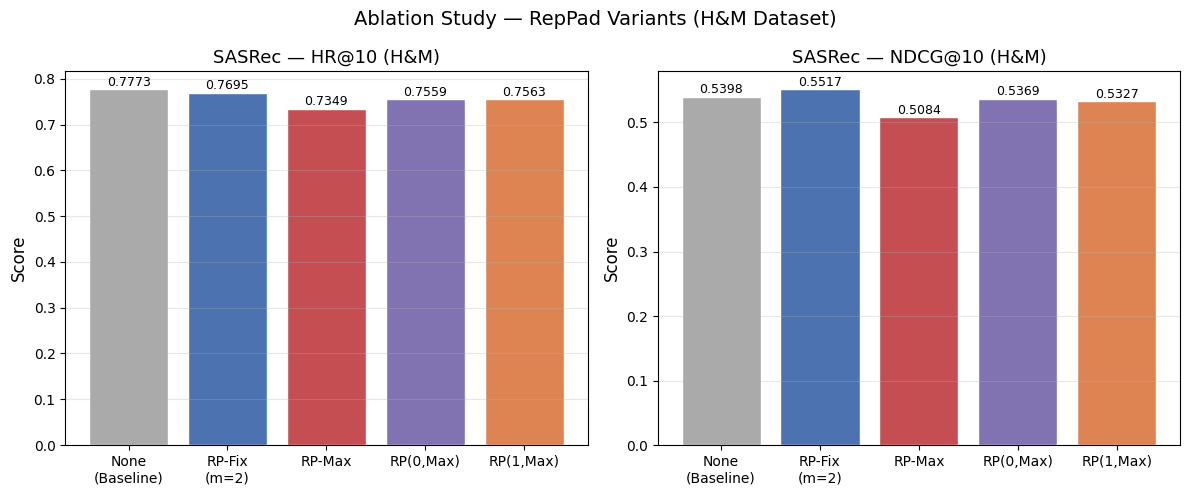

Saved: ablation_study.png


In [37]:
# ── Ablation bar chart (Figure 2 equivalent from paper) ──────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
variant_labels = ['None\n(Baseline)', 'RP-Fix\n(m=2)', 'RP-Max', 'RP(0,Max)', 'RP(1,Max)']

for ax, metric in zip(axes, ['HR@10', 'NDCG@10']):
    vals  = [ablation_results[v][metric] for v in ABLATION_VARIANTS]
    clrs  = ['#aaaaaa', '#4C72B0', '#C44E52', '#8172B2', '#DD8452']
    bars  = ax.bar(variant_labels, vals, color=clrs, edgecolor='white')
    ax.set_title(f'SASRec — {metric} (H&M)', fontsize=13)
    ax.set_ylabel('Score', fontsize=12)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.0005,
                f'{val:.4f}', ha='center', va='bottom', fontsize=9)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Ablation Study — RepPad Variants (H&M Dataset)', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PATH, 'ablation_study.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: ablation_study.png')

In [28]:
# ============================================================
# Cold-User Targeted RepPad
# Enhancement: apply RepPad only to short/cold users
# ============================================================

# Use train sequence lengths only
train_lengths = [
    len(seq[:-2]) for seq in user_sequences.values()
    if len(seq) >= 3
]

# Try 25th percentile first: only the shortest users get RepPad
COLD_THRESHOLD = int(np.percentile(train_lengths, 25))

print(f"Cold-user threshold: <= {COLD_THRESHOLD} items")
print(f"Cold users: {sum(l <= COLD_THRESHOLD for l in train_lengths):,} / {len(train_lengths):,}")


def cold_user_targeted_reppad(orig_seq, max_len, use_delimiter=True, cold_threshold=10):
    """
    Apply RepPad only to short/cold users.
    Longer sequences use standard zero padding.
    """

    train_items = orig_seq[:-3] if len(orig_seq) > 3 else orig_seq[:-2]
    target_items = orig_seq[1:-2] if len(orig_seq) > 3 else orig_seq[1:-1]

    if len(train_items) == 0:
        return seq_prepare([], max_len), seq_prepare([], max_len)

    # Long/active users: no RepPad
    if len(train_items) > cold_threshold:
        return seq_prepare(train_items, max_len), seq_prepare(target_items, max_len)

    # Cold/short users: original RepPad logic
    unit_len = len(train_items) + (1 if use_delimiter else 0)
    max_pad_num = int(max_len / unit_len)

    if max_pad_num <= 1:
        return seq_prepare(train_items, max_len), seq_prepare(target_items, max_len)

    pad_num = random.randint(1, max_pad_num)

    final_input = list(train_items)
    final_target = list(target_items)

    for _ in range(pad_num):
        if use_delimiter:
            final_input = list(train_items) + [0] + final_input
            final_target = list(target_items) + [0] + final_target
        else:
            final_input = list(train_items) + final_input
            final_target = list(target_items) + final_target

    return seq_prepare(final_input, max_len), seq_prepare(final_target, max_len)


class ColdUserTargetedDataset(Dataset):
    def __init__(self, user_sequences, max_len, use_delimiter=True, cold_threshold=10):
        self.user_ids = list(user_sequences.keys())
        self.sequences = user_sequences
        self.max_len = max_len
        self.use_delim = use_delimiter
        self.cold_threshold = cold_threshold

    def __len__(self):
        return len(self.user_ids)

    def __getitem__(self, idx):
        uid = self.user_ids[idx]
        seq = self.sequences[uid]

        inp, tgt = cold_user_targeted_reppad(
            seq,
            self.max_len,
            use_delimiter=self.use_delim,
            cold_threshold=self.cold_threshold
        )

        return torch.tensor(inp, dtype=torch.long), torch.tensor(tgt, dtype=torch.long)


print("Cold-User Targeted RepPad is ready.")

Cold-user threshold: <= 7 items
Cold users: 8,181 / 30,000
Cold-User Targeted RepPad is ready.


In [29]:
# ============================================================
# Experiment: SASRec + Cold-User Targeted RepPad
# ============================================================

gc.collect()
torch.cuda.empty_cache()

cold_dataset_sas = ColdUserTargetedDataset(
    user_sequences=user_sequences,
    max_len=MAX_SEQ_LEN,
    use_delimiter=True,
    cold_threshold=COLD_THRESHOLD
)

cold_loader_sas = DataLoader(
    cold_dataset_sas,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

sas_cold = SASRec(
    NUM_ITEMS,
    EMBED_DIM,
    MAX_SEQ_LEN,
    num_heads=1,
    num_layers=2
).to(DEVICE)

sas_cold_metrics, sas_cold_losses = train_model(
    sas_cold,
    cold_loader_sas,
    val_loader,
    test_loader,
    NUM_ITEMS,
    TOP_K,
    DEVICE,
    num_epochs=50,
    lr=LR,
    patience=PATIENCE,
    model_name="SASRec_ColdUserTargetedRepPad",
    use_amp=False
)

print("\n--- SASRec + Cold-User Targeted RepPad Test Results ---")
for k, v in sas_cold_metrics.items():
    print(f"{k}: {v:.4f}")

/usr/local/lib/python3.12/dist-packages/torch/nn/modules/activation.py:1336: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(


[SASRec_ColdUserTargetedRepPad] Epoch   1/50 | Loss: 10.4340 | Val NDCG@10: 0.3557 | Time: 45.5s
[SASRec_ColdUserTargetedRepPad] Epoch   5/50 | Loss: 8.7391 | Val NDCG@10: 0.5265 | Time: 45.7s
[SASRec_ColdUserTargetedRepPad] Epoch  10/50 | Loss: 6.8523 | Val NDCG@10: 0.5354 | Time: 45.7s
[SASRec_ColdUserTargetedRepPad] Epoch  15/50 | Loss: 5.7513 | Val NDCG@10: 0.5351 | Time: 45.7s
[SASRec_ColdUserTargetedRepPad] Epoch  20/50 | Loss: 5.1773 | Val NDCG@10: 0.5236 | Time: 45.7s
[SASRec_ColdUserTargetedRepPad] Epoch  25/50 | Loss: 4.7960 | Val NDCG@10: 0.5207 | Time: 45.7s
Early stopping at epoch 29

--- SASRec + Cold-User Targeted RepPad Test Results ---
HR@5: 0.6382
HR@10: 0.7598
HR@20: 0.8633
NDCG@5: 0.5015
NDCG@10: 0.5411
NDCG@20: 0.5674


In [30]:
comparison = {
    "SASRec Baseline": sas_base_metrics,
    "SASRec + RepPad": sas_rp_metrics,
    "SASRec + Adaptive RepPad": sas_adaptive_metrics,
    "SASRec + Cold-User Targeted RepPad": sas_cold_metrics,
}

comparison_df = pd.DataFrame(comparison).T
print(comparison_df[["HR@5", "HR@10", "HR@20", "NDCG@5", "NDCG@10", "NDCG@20"]].round(4))

                                      HR@5   HR@10   HR@20  NDCG@5  NDCG@10  \
SASRec Baseline                     0.6558  0.7773  0.8779  0.5132   0.5524   
SASRec + RepPad                     0.6392  0.7686  0.8701  0.4969   0.5387   
SASRec + Adaptive RepPad            0.6304  0.7607  0.8584  0.4935   0.5357   
SASRec + Cold-User Targeted RepPad  0.6382  0.7598  0.8633  0.5015   0.5411   

                                    NDCG@20  
SASRec Baseline                      0.5779  
SASRec + RepPad                      0.5645  
SASRec + Adaptive RepPad             0.5604  
SASRec + Cold-User Targeted RepPad   0.5674  


## 10. Saving Outputs

In [38]:
# ── Save all results ──────────────────────────────────────────────────────────
results_df.to_csv(os.path.join(OUTPUT_PATH, 'reppad_hm_results.csv'))
ablation_df.to_csv(os.path.join(OUTPUT_PATH, 'reppad_hm_ablation.csv'))

print('Files saved to /kaggle/working:')
for f in os.listdir(OUTPUT_PATH):
    print(f'  {f}')

Files saved to /kaggle/working:
  loss_convergence.png
  reppad_hm_results.csv
  GRU4Rec_Baseline_best.pt
  SASRec_rp_max_best.pt
  .virtual_documents
  ablation_study.png
  SASRec_rp_1_max_best.pt
  reppad_hm_ablation.csv
  GRU4Rec_RepPad_best.pt
  SASRec_Baseline_best.pt
  GRU4Rec_Baseline_final.pt
  metric_comparison.png
  SASRec_RepPad_best.pt
  SASRec_none_best.pt
  GRU4Rec_Baseline_metrics.json
  SASRec_rp_fix_best.pt
  SASRec_rp_0_max_best.pt


In [ ]:
# ── Save all models & results ─────────────────────────────────────────────────
import json
import shutil

# Save all model weights
models_to_save = {
    'GRU4Rec_Baseline'  : gru_baseline,
    'GRU4Rec_RepPad'    : gru_reppad,
    'SASRec_Baseline'   : sas_baseline,
    'SASRec_RepPad'     : sas_reppad,
}

for name, model in models_to_save.items():
    path = os.path.join(OUTPUT_PATH, f'{name}_final.pt')
    torch.save({
        'model_state_dict' : model.state_dict(),
        'num_items'        : NUM_ITEMS,
        'embed_dim'        : EMBED_DIM,
        'model_name'       : name,
    }, path)
    print(f'Saved: {path}')

# Save all metrics to JSON
all_metrics = {
    'GRU4Rec_Baseline'  : gru_base_metrics,
    'GRU4Rec_RepPad'    : gru_rp_metrics,
    'SASRec_Baseline'   : sas_base_metrics,
    'SASRec_RepPad'     : sas_rp_metrics,
}

metrics_path = os.path.join(OUTPUT_PATH, 'all_metrics.json')
with open(metrics_path, 'w') as f:
    json.dump(all_metrics, f, indent=2)
print(f'Saved: {metrics_path}')

# List all saved files
print('\nAll files in /kaggle/working:')
for f in sorted(os.listdir(OUTPUT_PATH)):
    size = os.path.getsize(os.path.join(OUTPUT_PATH, f))
    print(f'  {f} — {size/1e6:.2f} MB')

---
## Summary

| What | Detail |
|------|--------|
| Dataset | H&M Personalized Fashion Recommendations |
| Preprocessing | 5-core filtering, chronological ordering, leave-one-out split |
| Models | GRU4Rec, SASRec |
| Augmentation | RepPad RP(1,Max) with delimiter (best variant per paper) |
| Metrics | HR@5/10/20, NDCG@5/10/20 |
| Max Seq Len | 50 (consistent with paper short-sequence datasets) |

**Key expected outcome:** RepPad improves both GRU4Rec and SASRec on H&M (a short-sequence dataset) — consistent with the paper's findings of up to 60.3% improvement on GRU4Rec and 24.3% on SASRec.